In [1]:
import os
from langchain_openai import ChatOpenAI
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate

In [2]:
load_dotenv()  # Load environment variables from .env file
os.environ["OPENAI_API_KEY"] = os.getenv("OPEN_API_KEY")

In [3]:
llm = ChatOpenAI(model="gpt-4o-mini")

In [4]:
class State(TypedDict):
    applicant_details: str
    job_description: str
    experience_level: str
    skill_match: str
    response: str

In [5]:
workflow = StateGraph(State)

In [6]:
def categorize_experience(state: State) -> State:
    print(f"Categorizing experience for applicant details")
    prompt = ChatPromptTemplate.from_template("Based on the following job application, categorize the candidate as 'Entry-level', 'Mid-level', or 'Senior-level'"
    "Applicant Details: {applicant_details}")
    chain =prompt | llm
    experience_level = chain.invoke({"applicant_details": state["applicant_details"]}).content
    print(f"Experience level categorized as: {experience_level}")
    return {"experience_level": experience_level}

def assess_skillset(state: State) -> State:
    print(f"Assessing the skillset of candidate:")
    prompt = ChatPromptTemplate.from_template("Based on the job description provided below, assess the candidate's skillset. Respond with either 'Match' or 'No Match'"
    "Job Description: {job_description}"
    "Applicant Details: {applicant_details}")
    chain = prompt | llm
    skill_match = chain.invoke({"applicant_details": state["applicant_details"], "job_description": state["job_description"]}).content
    print(f"Skill match assessed as: {skill_match}")
    return {"skill_match": skill_match}

def schedule_interview(state: State) -> State:
    print(f"Scheduling interview based on skill match and experience level")
    return {"response": "Candidate has been shortlisted for an interview."}

def escalate_to_hr(state: State) -> State:
    print(f"Escalating to HR for further review")
    return {"response": "Candidate has senior-level experience and requires further review by HR."}

def reject_application(state: State) -> State:
    print(f"Rejecting application based on skill match and experience level")
    return {"response": "Candidate does not meet the required criteria and has been rejected."}

In [7]:
workflow.add_node("categorize_experience", categorize_experience)
workflow.add_node("assess_skillset", assess_skillset)
workflow.add_node("schedule_interview", schedule_interview)
workflow.add_node("escalate_to_hr", escalate_to_hr)
workflow.add_node("reject_application", reject_application)

In [8]:
def route_application(state: State) -> str:
    if state["skill_match"] == "Match":
        return "schedule_interview"
    elif state["experience_level"] == "Senior-level":
        return "escalate_to_hr"
    else:
        return "reject_application"

In [9]:
workflow.add_edge("categorize_experience", "assess_skillset")
workflow.add_conditional_edges("assess_skillset",route_application)

In [10]:
workflow.add_edge(START, "categorize_experience")
workflow.add_edge("assess_skillset", END)
workflow.add_edge("schedule_interview", END)
workflow.add_edge("escalate_to_hr", END)
workflow.add_edge("reject_application", END)

In [11]:
app = workflow.compile()

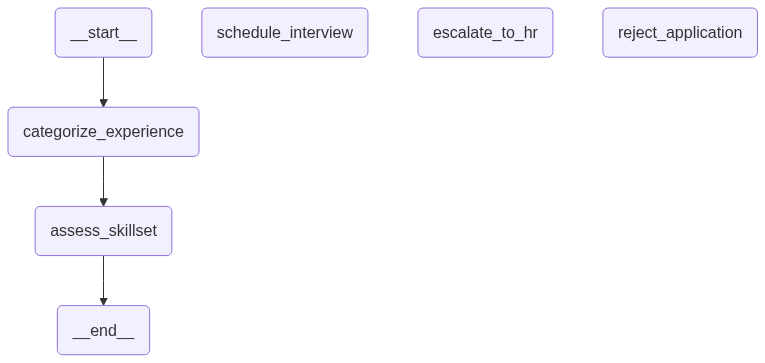

In [12]:
from IPython.display import display, Image
from langchain_core.runnables.graph import MermaidDrawMethod 

display(Image(app.get_graph().draw_mermaid_png(draw_method=MermaidDrawMethod.API)))

In [13]:
def run_candidate_screening(applicant_details: str, job_description: str) -> str:
    initial_state = {"applicant_details": applicant_details, "job_description": job_description}
    final_state = app.invoke(initial_state)
    return {"experience_level": final_state["experience_level"], 
    "skill_match": final_state["skill_match"], 
    "response": final_state["response"]}

In [ ]:
from io import BytesIO
from pypdf import PdfReader

with open(r"F:\All People Documents\Hyma\python\sample_rag_application\Raghavendra_Rongali.pdf", "rb") as f:
    pdf_data = f.read()

applicant_details = "\n".join(
    page.extract_text() or ""
    for page in PdfReader(BytesIO(pdf_data)).pages
)

with open(
    r"F:\All People Documents\Hyma\python\sample_rag_application\Job Description.txt",
    "r",
    encoding="utf-8-sig",
) as f:
    job_description = f.read()

results = run_candidate_screening(applicant_details, job_description)
print(f"Screening Results: ")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")

Categorizing experience for applicant details
Experience level categorized as: Based on the provided job application details, the candidate Raghavendra Rongali can be categorized as a **Senior-level** applicant. 

**Reasons for this categorization:**

1. **Years of Experience**: The candidate has over 5 years of software engineering experience, which typically qualifies for a senior-level position.

2. **Roles and Responsibilities**: The application highlights responsibilities such as architecting workflows, building production-grade applications, and leading technical delivery, which are indicative of senior-level roles.

3. **Complex Skills**: The candidate demonstrates proficiency in advanced technical skills and emerging technologies in AI/LLM engineering, microservices development, and cloud infrastructure (AWS), further supporting their senior-level status.

4. **Projects and Leadership**: The candidate has held positions like Sr. Associate and Sr. Software Engineer, suggesting t

In [21]:
with open(r"C:\Users\DELL\Downloads\RAG_Testing\HYMA_REDDY.pdf","rb") as f:
    pdf_data = f.read()

applicant_details = "\n".join(
    page.extract_text() or ""
    for page in PdfReader(BytesIO(pdf_data)).pages
)

with open(
    r"F:\All People Documents\Hyma\python\sample_rag_application\Job Description.txt",
    "r",
    encoding="utf-8-sig",
) as f:
    job_description = f.read()

results = run_candidate_screening(applicant_details, job_description)
print(f"Screening Results: ")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")

Categorizing experience for applicant details
Experience level categorized as: Based on the provided job application details, the candidate, Hyma Reddy, appears to be categorized as an **Entry-level** applicant. 

### Justification:
1. **Professional Experience**: The candidate has limited professional experience, with only apprenticeship and internship positions listed. This suggests they are still at the beginning stages of their career.
   
2. **Education Qualification**: The candidate is pursuing a Bachelor's degree in Artificial Intelligence & Machine Learning, which typically aligns with entry-level positions upon graduation.

3. **Project Work**: The candidate has completed academic projects, which is common for entry-level applicants who are looking to showcase their skills in practical applications.

4. **Skill Set**: While the candidate has relevant skills and knowledge, the overall experience still qualifies them as entry-level, especially due to the relatively short duratio